In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
combine_tracking = pd.read_csv("data/combine_tracking.csv")
combine_results = pd.read_csv("data/combine_results.csv")

# Combine Results

We are viewing offensive linemen, so we will first get a look at all of our linemen provided to us in the data set

In [3]:
oline = combine_results.loc[
    (combine_results['combine_position'] == 'OL'),
    ['nfl_id', 'combine_weight']
]

oline['weight'] = oline['combine_weight'] / 2.20462 # Convert to kg

In [4]:
drills = combine_tracking.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

In [5]:
drills = drills.sort_values(
    ['event_id', 'time']
).copy()

In [6]:
drills.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,weight
40231,2024,20240303100900_1709489409250_000,57126,PLAYER,2024-03-03T18:10:02.900,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.766667,-0.800000,0.833333,2.473077,0.001111,102.479072,145.603324
40232,2024,20240303100900_1709489409250_000,57126,PLAYER,2024-03-03T18:10:03.000,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.833333,-0.800000,1.073333,3.117772,0.004444,99.111357,145.603324
40233,2024,20240303100900_1709489409250_000,57126,PLAYER,2024-03-03T18:10:03.100,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.000000,-0.833333,1.693333,4.376530,0.027800,94.744899,145.603324
40234,2024,20240303100900_1709489409250_000,57126,PLAYER,2024-03-03T18:10:03.200,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.200000,-0.833333,2.080000,5.453419,0.040000,91.009917,145.603324
40235,2024,20240303100900_1709489409250_000,57126,PLAYER,2024-03-03T18:10:03.300,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.433333,-0.833333,2.703333,5.998046,0.054444,89.081651,145.603324


In [7]:
drill_average = (
    drills.groupby(['nfl_id', 'drill_name'])
    .agg(
        average_acceleration=('a', 'mean'),
        weight=('weight', 'first')
    )
    .reset_index()
)

In [8]:
drill_average['Force'] = (
    drill_average['average_acceleration'] *
    drill_average['weight']
)

In [12]:
drill_average['drill_name'] = drill_average['drill_name'].replace({
    'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE': 'Wave Drill',
    'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT': 'Pull Deep Short Left',
    'OL_PULL_DRILL_FOLD_BLOCK_RIGHT': 'Pull Fold Right',
    'OL_PULL_DRILL_LONG_PULL_RIGHT': 'Pull Long Right',
    'PASS_PRO-MIRROR_DRILL': 'Mirror Drill',
    'PASS_RUSH_DROP': 'Rush Drop',
    'SCREEN_DRILL': 'Screen Drill',
    'FORTY_YARD_DASH': '40 yd dash',
    'SHORT_SHUTTLE': 'Short Shuttle',
    'THREE_CONE_DRILL': '3-cone drill'
})

In [13]:
drill_average

,nfl_id,drill_name,average_acceleration,weight,Force
0,55870,Wave Drill,2.973460,141.974581,422.155739
1,55870,Pull Deep Short Left,2.842468,141.974581,403.558256
2,55870,Pull Fold Right,2.458750,141.974581,349.079931
3,55870,Pull Long Right,3.005433,141.974581,426.695094
4,55870,Mirror Drill,3.640385,141.974581,516.842145
...,...,...,...,...,...
982,58994,Pull Fold Right,2.244284,135.624280,304.379462
983,58994,Pull Long Right,3.779478,135.624280,512.588919
984,58994,Mirror Drill,3.011268,135.624280,408.401082
985,58994,Rush Drop,2.280800,135.624280,309.331913


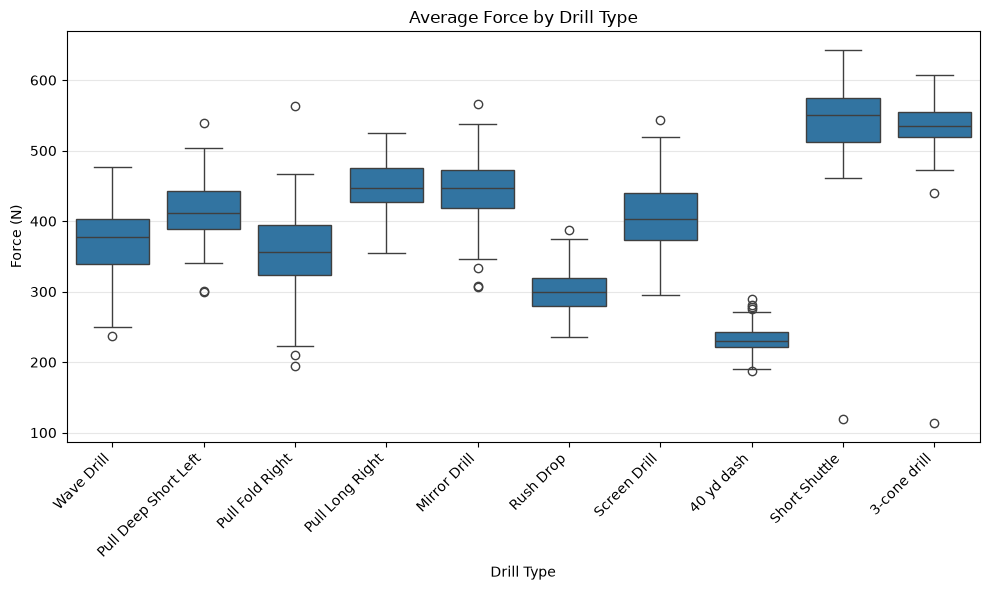

In [16]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=drill_average,
    x='drill_name',
    y='Force'
)

plt.title('Average Force by Drill Type')
plt.xlabel('Drill Type')
plt.ylabel('Force (N)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()